In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Cleaned Dataset

df = pd.read_csv("../dataset/online_retail_II_cleaned.csv")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Invoice"] = df["Invoice"].astype(str)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (1027017, 11)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancelled,Is_Return,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.0


In [3]:

# Prepare Valid Customer Transactions

sales_df = df[
    (~df["Is_Cancelled"].astype(bool)) &
    (~df["Is_Return"].astype(bool)) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

# Keep records with valid Customer IDs
sales_df = sales_df.dropna(subset=["Customer ID"]).copy()

# Remove cancelled invoices and invalid sales
sales_df["Invoice"] = sales_df["Invoice"].astype(str)

sales_df = sales_df[
    ~sales_df["Invoice"].str.startswith("C", na=False)
].copy()

print("Valid Customer Transactions:", len(sales_df))
print("Unique Customers:", sales_df["Customer ID"].nunique())


Valid Customer Transactions: 779425
Unique Customers: 5878


In [4]:

# Calculate Reference Date

reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)


Reference Date: 2011-12-10 12:50:00


In [5]:

# Calculate RFM Metrics

rfm = sales_df.groupby("Customer ID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "Invoice": "nunique",
    "Sales": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print("RFM Analysis Completed!")

rfm.head()


RFM Analysis Completed!


,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [6]:

# Calculate RFM Scores

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

print("RFM Scores Generated Successfully!")

rfm.head()


RFM Scores Generated Successfully!


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346.0,326,12,77556.46,2,5,5,12
12347.0,2,8,4921.53,5,4,5,14
12348.0,75,5,2019.40,3,4,4,11
12349.0,19,4,4428.69,5,3,5,13
12350.0,310,1,334.40,2,1,2,5


In [7]:

# Create Customer Segments

rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4),

        (rfm["R_Score"] >= 3) &
        (rfm["F_Score"] >= 4),

        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] >= 3) &
        (rfm["F_Score"] <= 2)
    ],
    [
        "Champions",
        "Loyal Customers",
        "At Risk",
        "New or Potential Customers"
    ],
    default="Others"
)

print("Customer Segmentation Completed!")

rfm[["Recency", "Frequency", "Monetary",
     "RFM_Score", "Segment"]].head(10)


Customer Segmentation Completed!


,Recency,Frequency,Monetary,RFM_Score,Segment
Customer ID,,,,,
12346.0,326,12,77556.46,12,At Risk
12347.0,2,8,4921.53,14,Champions
12348.0,75,5,2019.40,11,Loyal Customers
12349.0,19,4,4428.69,13,Others
12350.0,310,1,334.40,5,Others
12351.0,375,1,300.93,5,Others
12352.0,36,10,2849.84,13,Champions
12353.0,204,2,406.76,6,Others
12354.0,232,1,1079.40,6,Others


Segment
Others                        2231
Champions                     1289
At Risk                        825
New or Potential Customers     825
Loyal Customers                708
Name: count, dtype: int64


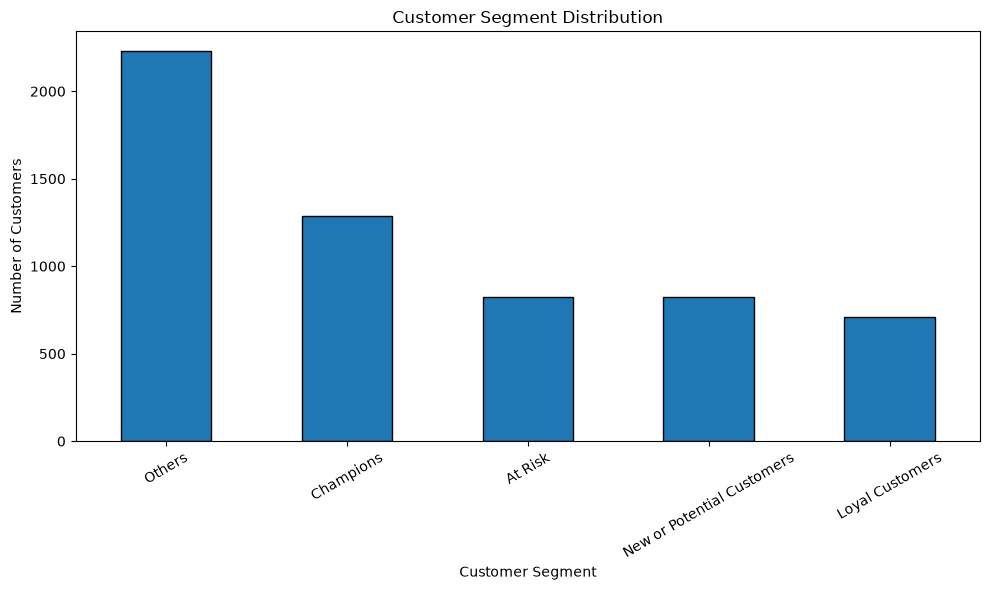

In [8]:

# Customer Segment Distribution

segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

plt.figure(figsize=(10, 6))

segment_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [9]:

# Prepare Data for K-Means Clustering

rfm_features = rfm[[
    "Recency",
    "Frequency",
    "Monetary"
]].copy()

# Reduce the effect of highly skewed values
rfm_log = np.log1p(rfm_features)

# Standardize the data
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("Data prepared for K-Means successfully!")
print("Number of Customers:", len(rfm_scaled))


Data prepared for K-Means successfully!
Number of Customers: 5878


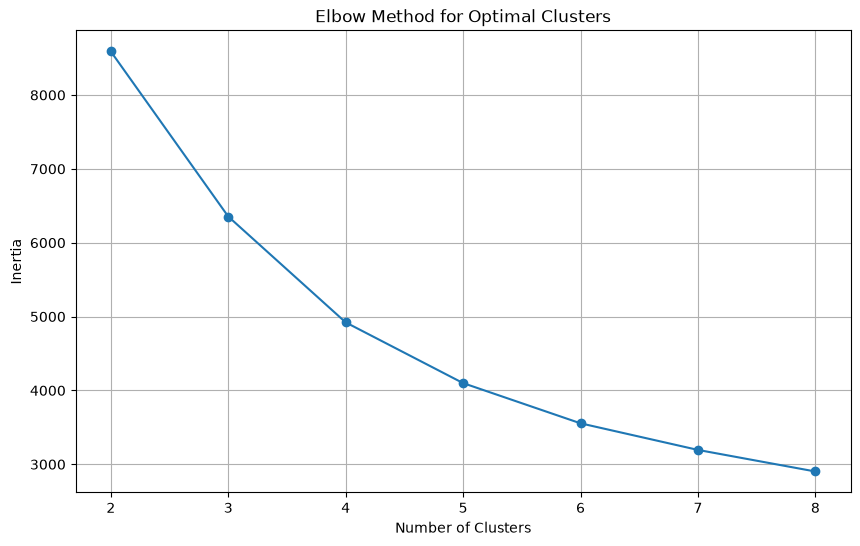

In [10]:

# Elbow Method

inertia_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 9),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()


In [11]:

# Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")

print("\nCustomer Distribution:")
print(rfm["Cluster"].value_counts().sort_index())


K-Means Clustering Completed!

Customer Distribution:
Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [12]:

# Evaluate Clustering Performance

silhouette = silhouette_score(
    rfm_scaled,
    rfm["Cluster"]
)

print("Silhouette Score:", round(silhouette, 4))


Silhouette Score: 0.365


In [13]:

# Analyze Customer Clusters

cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

cluster_summary["Customer_Count"] = (
    rfm.groupby("Cluster").size()
)

print("Customer Cluster Summary:")
display(cluster_summary)


Customer Cluster Summary:


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,394.95,1.38,317.08,1973
1,28.30,3.05,857.49,1250
2,27.71,19.28,10731.16,1196
3,230.07,5.06,1948.50,1459


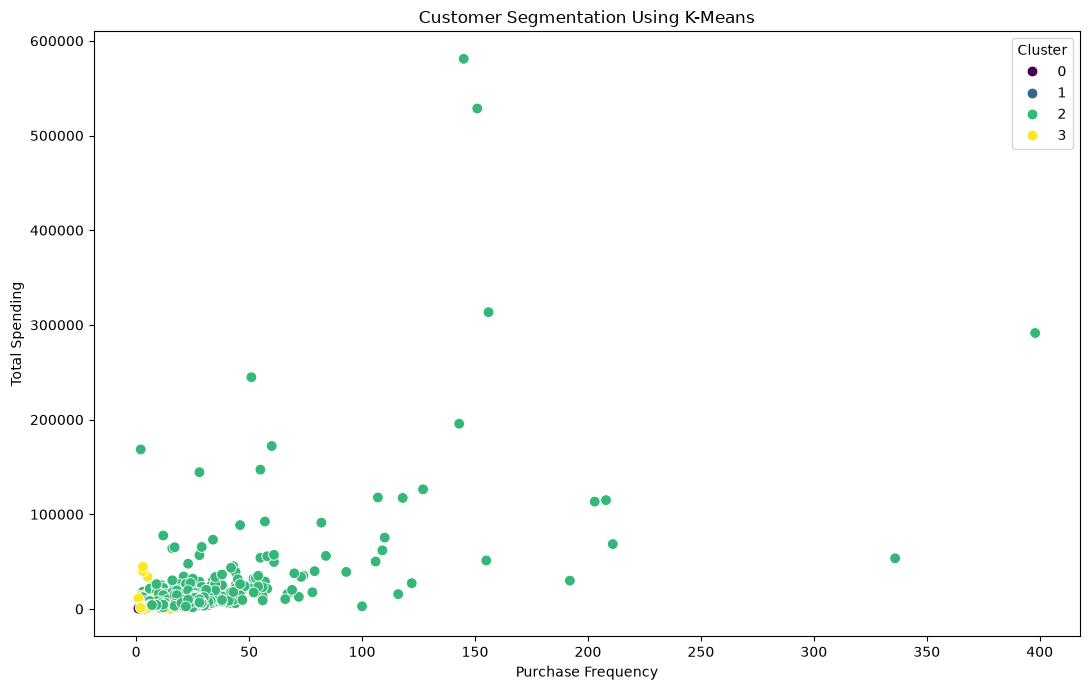

In [14]:

# Visualize Customer Clusters

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [15]:

# Save Customer Segmentation Results

output_path = "../dataset/customer_segmentation_results.csv"

rfm.to_csv(output_path)

print("Customer Segmentation Results Saved!")
print("File:", output_path)
print("Total Customers Analyzed:", len(rfm))


Customer Segmentation Results Saved!
File: ../dataset/customer_segmentation_results.csv
Total Customers Analyzed: 5878


In [16]:

# Final Customer Segmentation Report

print("=" * 60)
print("CUSTOMER SHOPPING BEHAVIOR ANALYTICS")
print("CUSTOMER SEGMENTATION REPORT")
print("=" * 60)

print("Total Customers:", len(rfm))

print("\nRFM Segment Distribution:")
print(rfm["Segment"].value_counts())

print("\nK-Means Cluster Distribution:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nAverage Customer Spending:",
      round(rfm["Monetary"].mean(), 2))

print("\nAverage Purchase Frequency:",
      round(rfm["Frequency"].mean(), 2))

print("\nAverage Recency:",
      round(rfm["Recency"].mean(), 2), "days")

print("\nSilhouette Score:", round(silhouette, 4))

print("\nCustomer Segmentation Completed Successfully!")
print("=" * 60)


CUSTOMER SHOPPING BEHAVIOR ANALYTICS
CUSTOMER SEGMENTATION REPORT
Total Customers: 5878

RFM Segment Distribution:
Segment
Others                        2231
Champions                     1289
At Risk                        825
New or Potential Customers     825
Loyal Customers                708
Name: count, dtype: int64

K-Means Cluster Distribution:
Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

Average Customer Spending: 2955.9

Average Purchase Frequency: 6.29

Average Recency: 201.33 days

Silhouette Score: 0.365

Customer Segmentation Completed Successfully!
